##Business Overview 
#

In [2]:
import pandas as pd

In [3]:
appointments = pd.read_csv(r"C:\Users\Smart\OneDrive\Desktop\py\apollo_appointments_fact.csv",
                          keep_default_na=False,
                          na_values=[""])

doctors = pd.read_csv(r"C:\Users\Smart\OneDrive\Desktop\py\apollo_doctors_dim.csv",
                      keep_default_na=False,
                          na_values=[""])

print(appointments.shape)
print(doctors.shape)

(75000, 52)
(320, 15)


In [4]:
# print(appointments)
# print(doctors)

      appointment_id patient_id doctor_id appointment_date appointment_day  \
0        APPT5000001  PAT117608   DOC1035       2023-11-15       Wednesday   
1        APPT5000002  PAT128732   DOC1049       2023-03-13          Monday   
2        APPT5000003  PAT137532   DOC1033       2022-02-07          Monday   
3        APPT5000004  PAT113284   DOC1288       2023-11-20          Monday   
4        APPT5000005  PAT107443   DOC1064       2024-02-02          Friday   
...              ...        ...       ...              ...             ...   
74995    APPT5074996  PAT124687   DOC1215       2024-02-04          Sunday   
74996    APPT5074997  PAT135901   DOC1236       2022-03-18          Friday   
74997    APPT5074998  PAT123568   DOC1163       2022-08-16         Tuesday   
74998    APPT5074999  PAT123394   DOC1278       2024-09-09          Monday   
74999    APPT5075000  PAT103005   DOC1072       2024-11-06       Wednesday   

       appointment_day_of_week  appointment_month appointment_q

#q1. How is appointment volume trending across months and quarters from 2022 to 2024? 

In [4]:
import pandas as pd
data = pd.read_csv(r"C:\Users\Smart\OneDrive\Desktop\py\apollo_appointments_fact.csv",
                   keep_default_na=False,
                          na_values=[""])
print(data.shape)

(75000, 52)


In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 75000 entries, 0 to 74999
Data columns (total 52 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   appointment_id              75000 non-null  str    
 1   patient_id                  75000 non-null  str    
 2   doctor_id                   75000 non-null  str    
 3   appointment_date            75000 non-null  str    
 4   appointment_day             75000 non-null  str    
 5   appointment_day_of_week     75000 non-null  int64  
 6   appointment_month           75000 non-null  int64  
 7   appointment_quarter         75000 non-null  str    
 8   appointment_year            75000 non-null  int64  
 9   appointment_hour            75000 non-null  int64  
 10  appointment_minute          75000 non-null  int64  
 11  time_slot                   75000 non-null  str    
 12  time_of_day                 75000 non-null  str    
 13  booking_date                75000 non-null

In [8]:
data.isnull().sum()

appointment_id                    0
patient_id                        0
doctor_id                         0
appointment_date                  0
appointment_day                   0
appointment_day_of_week           0
appointment_month                 0
appointment_quarter               0
appointment_year                  0
appointment_hour                  0
appointment_minute                0
time_slot                         0
time_of_day                       0
booking_date                      0
booking_lead_days                 0
booking_channel                   0
appointment_type                  0
specialty                         0
city                              0
state                             0
hospital_name                     0
patient_age                       0
age_group                         0
patient_gender                    0
patient_city_tier                 0
patient_chronic_condition         0
apollo_member                     0
membership_type             

In [22]:
data["appointment_date"] = pd.to_datetime(data["appointment_date"])

data["year"] = data["appointment_date"].dt.year
data["month"] = data["appointment_date"].dt.month

monthly = data.groupby(
    ["year", "month"]
)["appointment_id"].count().reset_index()

monthly.columns = [
    "year",
    "month",
    "Total_Appointments"
]

print(monthly)

    year  month  Total_Appointments
0   2022      1                2426
1   2022      2                2012
2   2022      3                2085
3   2022      4                1926
4   2022      5                2033
5   2022      6                1823
6   2022      7                1833
7   2022      8                1835
8   2022      9                2115
9   2022     10                2206
10  2022     11                2299
11  2022     12                2275
12  2023      1                2371
13  2023      2                2013
14  2023      3                2103
15  2023      4                1964
16  2023      5                2002
17  2023      6                1896
18  2023      7                1884
19  2023      8                1785
20  2023      9                2038
21  2023     10                2278
22  2023     11                2329
23  2023     12                2391
24  2024      1                2427
25  2024      2                2078
26  2024      3             

In [25]:
yearly = data.groupby("year")["appointment_id"].count()
print(yearly)

year
2022    24868
2023    25054
2024    25078
Name: appointment_id, dtype: int64


In [50]:
data["quarter"] = data["appointment_date"].dt.quarter
quarterly = data.groupby(["year", "quarter"])["appointment_id"].count().reset_index()

quarterly.columns = ["year", "quarter", "Total_Appointments"]

print(quarterly)


    year  quarter  Total_Appointments
0   2022        1                6523
1   2022        2                5782
2   2022        3                5783
3   2022        4                6780
4   2023        1                6487
5   2023        2                5862
6   2023        3                5707
7   2023        4                6998
8   2024        1                6538
9   2024        2                5899
10  2024        3                5777
11  2024        4                6864


#monthly line chart

In [5]:
import matplotlib.pyplot as plt

In [43]:
print(monthly.columns)

['year', 'month', 'Total_Appointments']


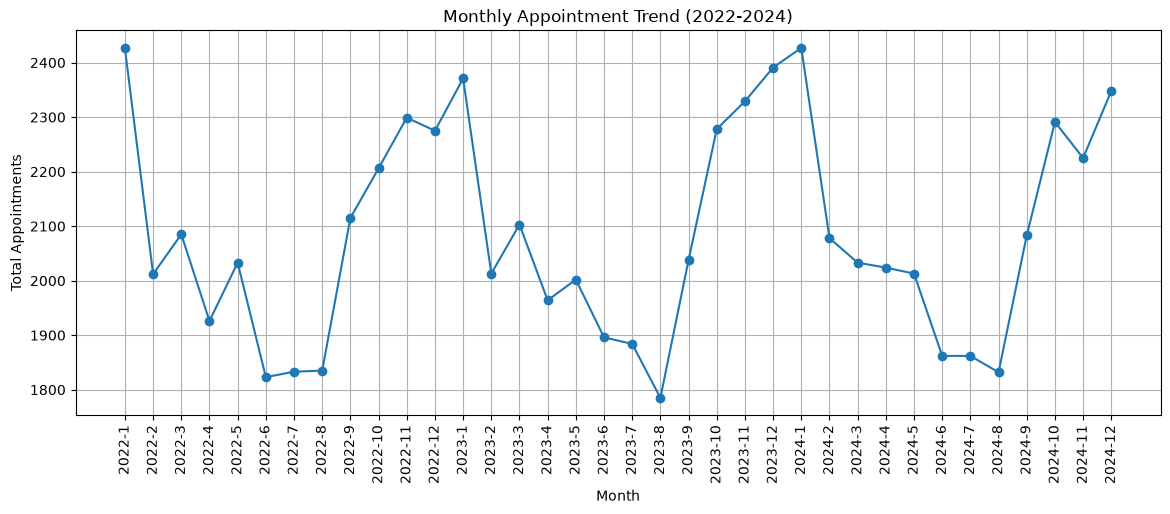

In [49]:
plt.figure(figsize=(14,5))

plt.plot(
    monthly["year"].astype(str) + "-" + monthly["month"].astype(str),
    monthly["Total_Appointments"],
    marker="o"
)

plt.title("Monthly Appointment Trend (2022-2024)")
plt.xlabel("Month")
plt.ylabel("Total Appointments")
plt.xticks(rotation=90)
plt.grid()
plt.show()

#Quarterly Bar Chart

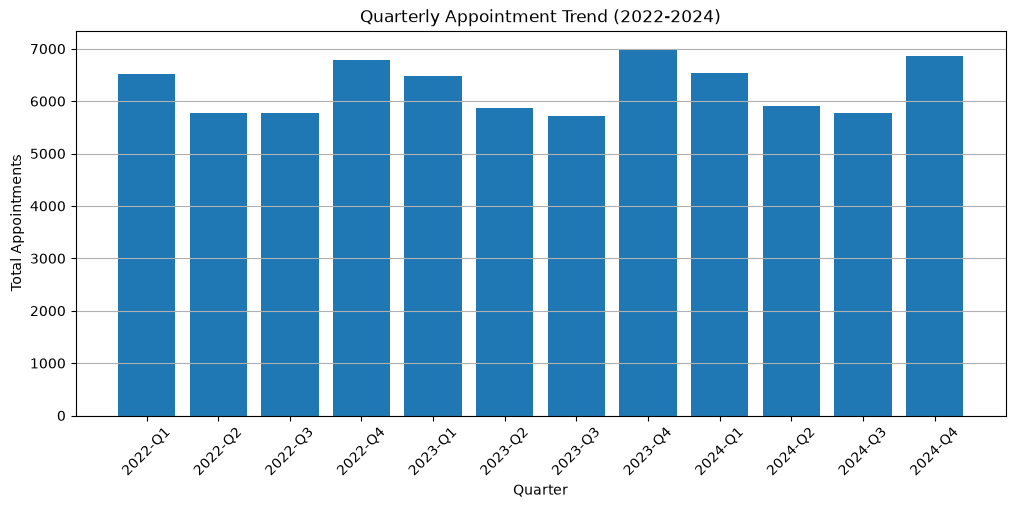

In [52]:
plt.figure(figsize=(12,5))

plt.bar(
    quarterly["year"].astype(str) + "-Q" + quarterly["quarter"].astype(str),
    quarterly["Total_Appointments"]
)

plt.title("Quarterly Appointment Trend (2022-2024)")
plt.xlabel("Quarter")
plt.ylabel("Total Appointments")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

#q.2 What is the split of outcomes across completed, no-show, cancelled, and scheduled appointments? 

In [56]:
status_analysis = data.groupby("appointment_status")["appointment_id"].count().reset_index()
status_analysis.columns = ["appointment_status", "total_appointment"]

print(status_analysis)


  appointment_status  total_appointment
0          Cancelled               5793
1          Completed              55275
2            No-Show              11584
3          Scheduled               2348


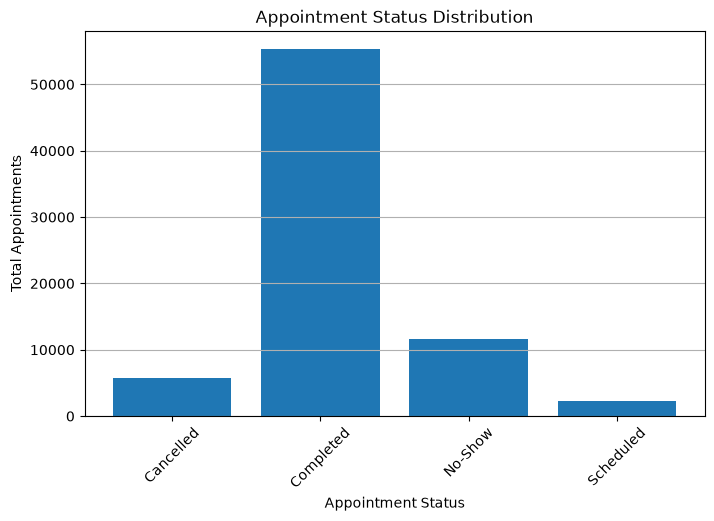

In [57]:
plt.figure(figsize=(8,5))

plt.bar(
    status_analysis["appointment_status"],
    status_analysis["total_appointment"]
)

plt.title("Appointment Status Distribution")
plt.xlabel("Appointment Status")
plt.ylabel("Total Appointments")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

In [ ]:
#q3.Which booking channels drive the highest volume and how does the channel mix look? 

In [61]:
#  Booking channel ke according appointments count
channel_analysis = data.groupby("booking_channel")["appointment_id"].count().reset_index()

#  Column names
channel_analysis.columns = ["booking_channel", "total_appointments"]

#  Percentage calculate
channel_analysis["percentage"] = ((
    channel_analysis["total_appointments"] / channel_analysis["total_appointments"].sum()
) * 100).round(2)

# Highest to lowest sorting
channel_analysis = channel_analysis.sort_values(
    by="total_appointments", ascending=False
)

print(channel_analysis)

  booking_channel  total_appointments  percentage
0      Apollo App               34042       45.39
4         Website               18545       24.73
1     Call Centre               11201       14.93
3         Walk-In                7501       10.00
2     Partner App                3711        4.95


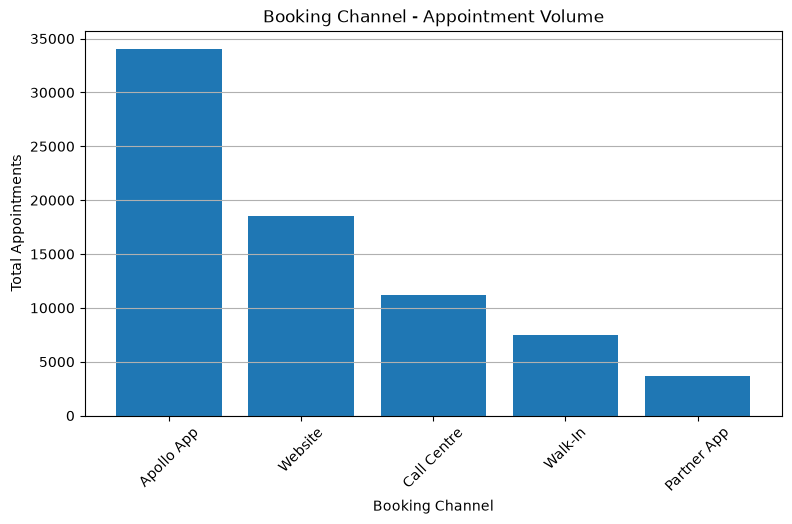

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9,5))

plt.bar(
    channel_analysis["booking_channel"],
    channel_analysis["total_appointments"]
)

plt.title("Booking Channel - Appointment Volume")
plt.xlabel("Booking Channel")
plt.ylabel("Total Appointments")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

#No-Show Analysis 

#q1.Which specialties and cities have the highest and lowest no-show rates? 


In [63]:
# Scheduled appointments ko exclude karna
no_show_data = data[
    data["appointment_status"].isin(["Completed", "No-Show", "Cancelled"])
].copy()

# No-Show ke liye 1 aur baaki ke liye 0
no_show_data["is_no_show"] = (
    no_show_data["appointment_status"] == "No-Show"
).astype(int)

In [64]:
specialty_analysis = no_show_data.groupby("specialty").agg(
    total_appointments=("appointment_id", "count"),
    no_show_appointments=("is_no_show", "sum")
).reset_index()

specialty_analysis["no_show_rate"] = (
    specialty_analysis["no_show_appointments"] /
    specialty_analysis["total_appointments"]
) * 100

specialty_analysis = specialty_analysis.sort_values(
    by="no_show_rate", ascending=False
)

print(specialty_analysis)

            specialty  total_appointments  no_show_appointments  no_show_rate
11         Psychiatry                2900                   711     24.517241
1         Dermatology                7566                  1608     21.252974
2                 ENT                5211                   988     18.959893
3       Endocrinology                2024                   355     17.539526
8       Ophthalmology                3103                   503     16.210119
5   General Physician               19654                  3049     15.513381
12        Pulmonology                2549                   394     15.457042
9        Orthopaedics                5419                   810     14.947407
4    Gastroenterology                2527                   377     14.918876
13            Urology                2222                   320     14.401440
6         Gynaecology                3991                   569     14.257078
0          Cardiology                4484                   629 

In [66]:
city_analysis = no_show_data.groupby("city").agg(
    total_appointments=("appointment_id", "count"),
    no_show_appointments=("is_no_show", "sum")
).reset_index()

city_analysis["no_show_rate"] = (
    city_analysis["no_show_appointments"] /
    city_analysis["total_appointments"]
) * 100

city_analysis = city_analysis.sort_values(
    by="no_show_rate", ascending=False
)

print(city_analysis)

          city  total_appointments  no_show_appointments  no_show_rate
12     Lucknow                3001                   516     17.194269
13      Mumbai                9734                  1659     17.043353
6        Delhi               10404                  1754     16.858900
2       Bhopal                2001                   336     16.791604
11     Kolkata                5701                   933     16.365550
10       Kochi                2690                   438     16.282528
0    Ahmedabad                3468                   561     16.176471
9       Jaipur                2653                   429     16.170373
7    Hyderabad                7229                  1160     16.046479
1    Bengaluru                8343                  1287     15.426106
3   Chandigarh                2406                   363     15.087282
4      Chennai                6702                  1005     14.995524
5   Coimbatore                2162                   306     14.153562
8     

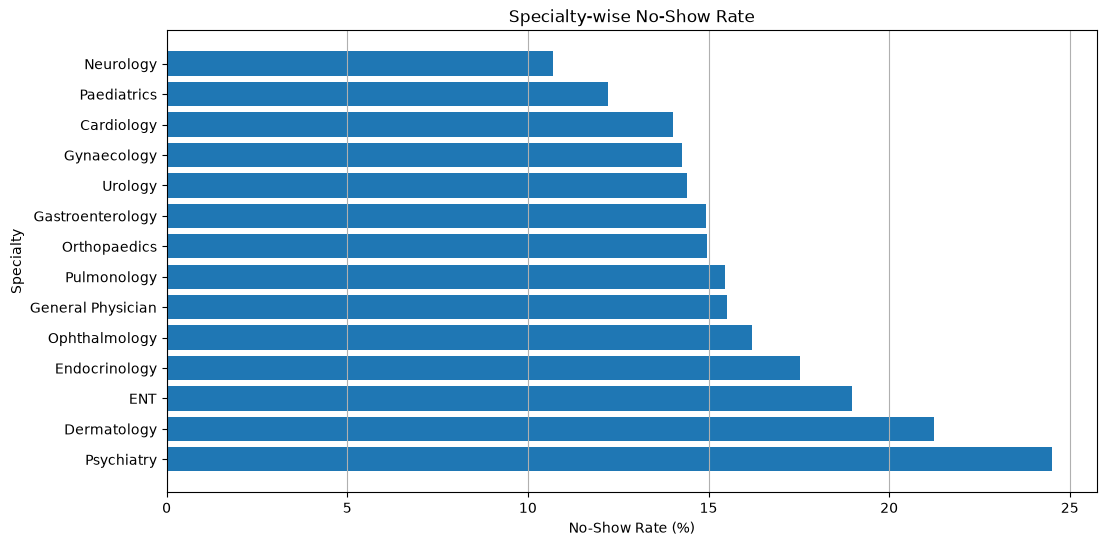

In [67]:
plt.figure(figsize=(12,6))

plt.barh(
    specialty_analysis["specialty"],
    specialty_analysis["no_show_rate"]
)

plt.title("Specialty-wise No-Show Rate")
plt.xlabel("No-Show Rate (%)")
plt.ylabel("Specialty")
plt.grid(axis="x")
plt.show()

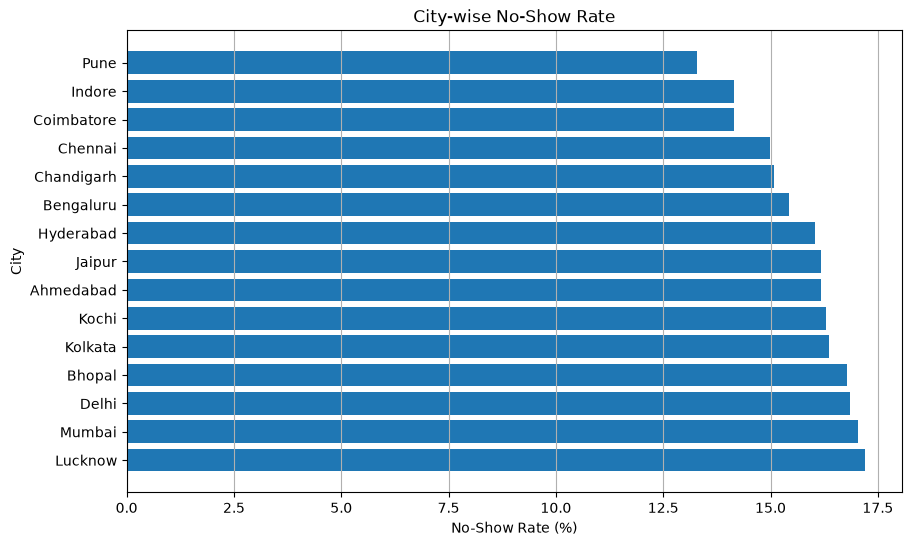

In [68]:
plt.figure(figsize=(10,6))

plt.barh(
    city_analysis["city"],
    city_analysis["no_show_rate"]
)

plt.title("City-wise No-Show Rate")
plt.xlabel("No-Show Rate (%)")
plt.ylabel("City")
plt.grid(axis="x")
plt.show()

In [69]:
print("Highest No-Show Specialty:")
print(specialty_analysis.head(1))

print("Lowest No-Show Specialty:")
print(specialty_analysis.tail(1))

print("Highest No-Show City:")
print(city_analysis.head(1))

print("Lowest No-Show City:")
print(city_analysis.tail(1))

Highest No-Show Specialty:
     specialty  total_appointments  no_show_appointments  no_show_rate
11  Psychiatry                2900                   711     24.517241
Lowest No-Show Specialty:
   specialty  total_appointments  no_show_appointments  no_show_rate
7  Neurology                4817                   515     10.691302
Highest No-Show City:
       city  total_appointments  no_show_appointments  no_show_rate
12  Lucknow                3001                   516     17.194269
Lowest No-Show City:
    city  total_appointments  no_show_appointments  no_show_rate
14  Pune                4009                   533     13.295086


#q2. How does booking lead time affect the probability of a no-show?

In [70]:
import matplotlib.pyplot as plt
import pandas as pd

# Step 1: Scheduled appointments ko exclude karna
lead_data = data[
    data["appointment_status"].isin(["Completed", "No-Show", "Cancelled"])
].copy()

# Step 2: Booking lead time ke groups banana
lead_data["lead_time_group"] = pd.cut(
    lead_data["booking_lead_days"],
    bins=[-1, 0, 7, 30, float("inf")],
    labels=["Same Day", "1-7 Days", "8-30 Days", "31+ Days"]
)

# Step 3: No-Show indicator banana
lead_data["is_no_show"] = (
    lead_data["appointment_status"] == "No-Show"
).astype(int)

# Step 4: Group-wise analysis
lead_analysis = lead_data.groupby(
    "lead_time_group", observed=True
).agg(
    total_appointments=("appointment_id", "count"),
    no_show_appointments=("is_no_show", "sum")
).reset_index()

# Step 5: No-Show Rate calculate karna
lead_analysis["no_show_rate"] = (
    lead_analysis["no_show_appointments"] /
    lead_analysis["total_appointments"]
) * 100

print(lead_analysis)

  lead_time_group  total_appointments  no_show_appointments  no_show_rate
0        Same Day               20180                  3193     15.822597
1        1-7 Days               41372                  6274     15.164846
2       8-30 Days               11100                  2117     19.072072


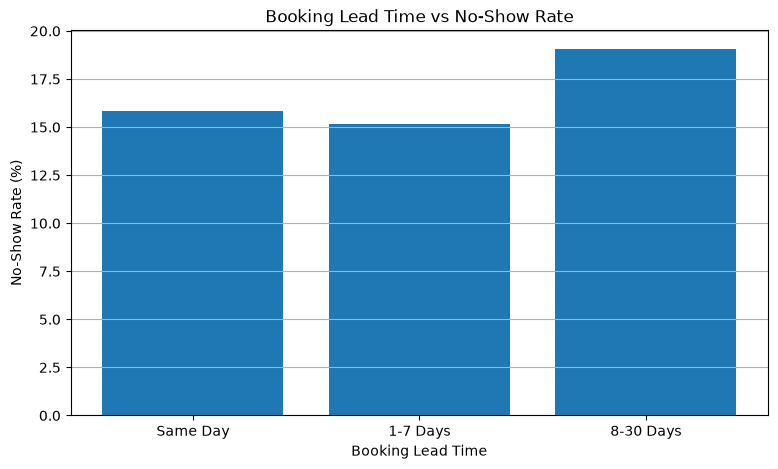

In [71]:
plt.figure(figsize=(9,5))

plt.bar(
    lead_analysis["lead_time_group"].astype(str),
    lead_analysis["no_show_rate"]
)

plt.title("Booking Lead Time vs No-Show Rate")
plt.xlabel("Booking Lead Time")
plt.ylabel("No-Show Rate (%)")
plt.grid(axis="y")
plt.show()

#q3.Do evening slots, weekends, and longer-lead bookings see higher dropout?

In [72]:
print(data.columns.tolist())

['appointment_id', 'patient_id', 'doctor_id', 'appointment_date', 'appointment_day', 'appointment_day_of_week', 'appointment_month', 'appointment_quarter', 'appointment_year', 'appointment_hour', 'appointment_minute', 'time_slot', 'time_of_day', 'booking_date', 'booking_lead_days', 'booking_channel', 'appointment_type', 'specialty', 'city', 'state', 'hospital_name', 'patient_age', 'age_group', 'patient_gender', 'patient_city_tier', 'patient_chronic_condition', 'apollo_member', 'membership_type', 'reminder_type', 'reminders_sent', 'patient_prior_visits', 'patient_prior_no_shows', 'is_first_visit', 'repeat_visit', 'visit_reason', 'appointment_status', 'no_show', 'no_show_flag', 'cancellation_reason', 'consultation_fee', 'discount_pct', 'actual_fee_charged', 'insurance_coverage', 'insurance_provider', 'insurance_covered_amount', 'patient_out_of_pocket', 'revenue_realized', 'payment_mode', 'wait_time_minutes', 'consultation_duration_min', 'patient_satisfaction_score', 'doctor_utilization_p

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

dropout_data = data[
    data["appointment_status"].isin(
        ["Completed", "No-Show", "Cancelled"]
    )
].copy()

dropout_data["is_dropout"] = (
    dropout_data["appointment_status"].isin(
        ["No-Show", "Cancelled"]
    )
).astype(int)

In [26]:
time_analysis = dropout_data.groupby("time_of_day").agg(
    total_appointments=("appointment_id", "count"),
    dropout_appointments=("is_dropout", "sum")
).reset_index()

time_analysis["dropout_rate"] = (
    time_analysis["dropout_appointments"] /
    time_analysis["total_appointments"]
) * 100

print(time_analysis.round(2))


  time_of_day  total_appointments  dropout_appointments  dropout_rate
0   Afternoon               23231                  5961         25.66
1     Evening               14553                  3835         26.35
2     Morning               34868                  7581         21.74


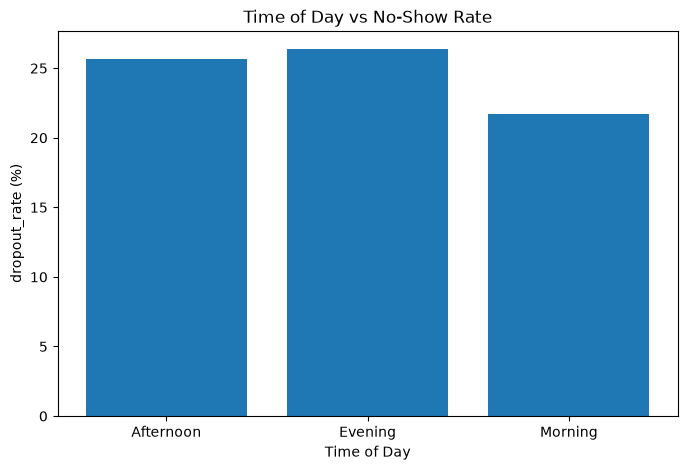

In [31]:
plt.figure(figsize=(8,5))

plt.bar(
    time_analysis["time_of_day"],
    time_analysis["dropout_rate"]
)

plt.title("Time of Day vs No-Show Rate")
plt.xlabel("Time of Day")
plt.ylabel("dropout_rate (%)")
plt.show()

In [16]:
dropout_data["day_type"] = dropout_data["appointment_day_of_week"].apply(
    lambda x: "Weekend" if x in [5, 6] else "Weekday"
)

day_analysis = dropout_data.groupby("day_type").agg(
    total_appointments=("appointment_id", "count"),
    no_show_appointments=("is_no_show", "sum")
).reset_index()

day_analysis["no_show_rate"] = (
    day_analysis["no_show_appointments"] /
    day_analysis["total_appointments"]
) * 100

print(day_analysis)

  day_type  total_appointments  no_show_appointments  no_show_rate
0  Weekday               51731                  7676     14.838298
1  Weekend               20921                  3908     18.679795


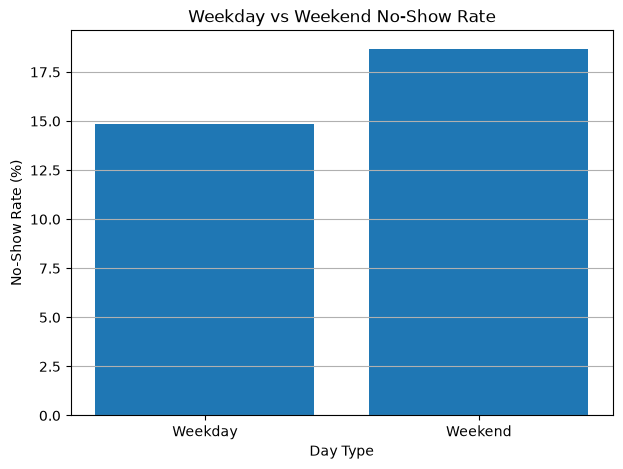

In [17]:
plt.figure(figsize=(7,5))

plt.bar(day_analysis["day_type"], day_analysis["no_show_rate"])

plt.title("Weekday vs Weekend No-Show Rate")
plt.xlabel("Day Type")
plt.ylabel("No-Show Rate (%)")
plt.grid(axis="y")

plt.show()

In [9]:
dropout_data["lead_time_group"] = pd.cut(
    dropout_data["booking_lead_days"],
    bins=[-1, 0, 7, 30, float("inf")],
    labels=["Same Day", "1-7 Days", "8-30 Days", "31+ Days"]
)

In [10]:
lead_analysis = dropout_data.groupby("lead_time_group", observed=True).agg(
    total_appointments=("appointment_id", "count"),
    no_show_appointments=("is_no_show", "sum")
).reset_index()

lead_analysis["no_show_rate"] = (
    lead_analysis["no_show_appointments"] /
    lead_analysis["total_appointments"]
) * 100

print(lead_analysis)

  lead_time_group  total_appointments  no_show_appointments  no_show_rate
0        Same Day               20180                  3193     15.822597
1        1-7 Days               41372                  6274     15.164846
2       8-30 Days               11100                  2117     19.072072


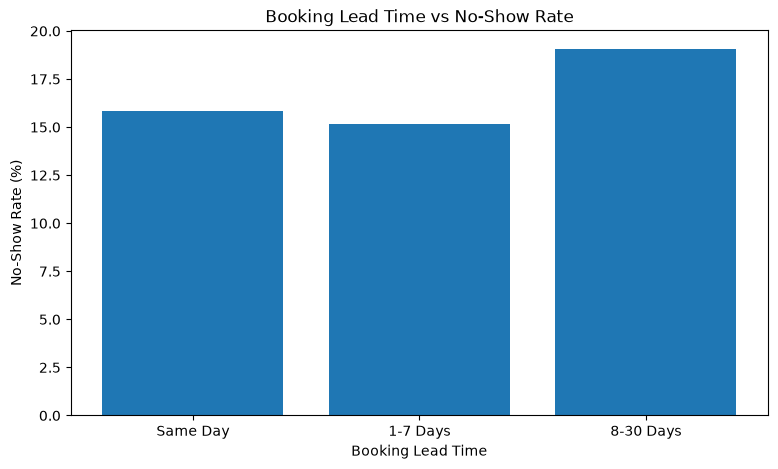

In [11]:
plt.figure(figsize=(9,5))

plt.bar(
    lead_analysis["lead_time_group"].astype(str),
    lead_analysis["no_show_rate"]
)

plt.title("Booking Lead Time vs No-Show Rate")
plt.xlabel("Booking Lead Time")
plt.ylabel("No-Show Rate (%)")
plt.show()

#q3. Which appointment types and booking channels carry the most no-show risk? 

In [18]:
no_show_data = data[
    data["appointment_status"].isin(["Completed", "No-Show", "Cancelled"])
].copy()

no_show_data["is_no_show"] = (
    no_show_data["appointment_status"] == "No-Show"
).astype(int)

In [19]:
type_analysis = no_show_data.groupby("appointment_type").agg(
    total_appointments=("appointment_id", "count"),
    no_show_appointments=("is_no_show", "sum")
).reset_index()

type_analysis["no_show_rate"] = (
    type_analysis["no_show_appointments"] /
    type_analysis["total_appointments"]
) * 100

type_analysis = type_analysis.sort_values(
    by="no_show_rate", ascending=False
)

print(type_analysis)

  appointment_type  total_appointments  no_show_appointments  no_show_rate
0       Home Visit                9742                  2557     26.247177
2    Video Consult               15349                  3232     21.056746
1        In-Clinic               47561                  5795     12.184353


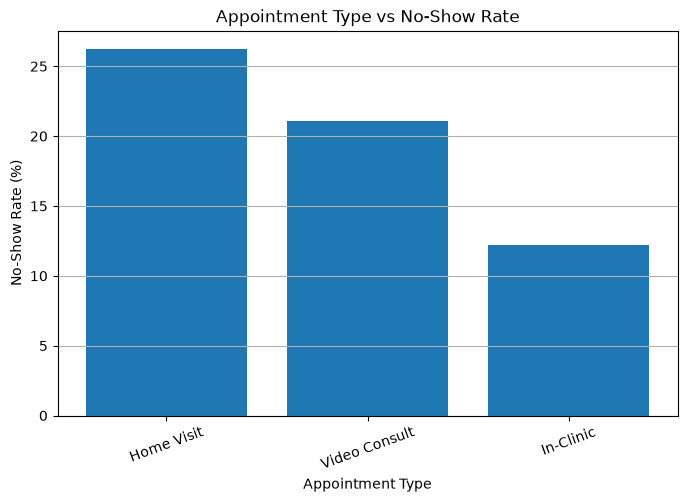

In [21]:
plt.figure(figsize=(8,5))

plt.bar(
    type_analysis["appointment_type"],
    type_analysis["no_show_rate"]
)

plt.title("Appointment Type vs No-Show Rate")
plt.xlabel("Appointment Type")
plt.ylabel("No-Show Rate (%)")
plt.xticks(rotation=20)
plt.grid(axis="y")
plt.show()

In [20]:
channel_analysis = no_show_data.groupby("booking_channel").agg(
    total_appointments=("appointment_id", "count"),
    no_show_appointments=("is_no_show", "sum")
).reset_index()

channel_analysis["no_show_rate"] = (
    channel_analysis["no_show_appointments"] /
    channel_analysis["total_appointments"]
) * 100

channel_analysis = channel_analysis.sort_values(
    by="no_show_rate", ascending=False
)

print(channel_analysis)

  booking_channel  total_appointments  no_show_appointments  no_show_rate
3         Walk-In                7281                  1520     20.876253
2     Partner App                3594                   651     18.113523
4         Website               17964                  3090     17.201069
1     Call Centre               10855                  1650     15.200368
0      Apollo App               32958                  4673     14.178652


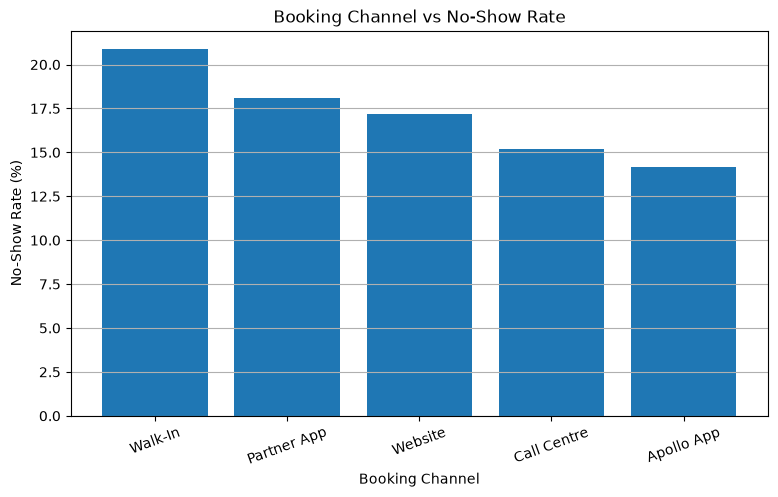

In [22]:
plt.figure(figsize=(9,5))

plt.bar(
    channel_analysis["booking_channel"],
    channel_analysis["no_show_rate"]
)

plt.title("Booking Channel vs No-Show Rate")
plt.xlabel("Booking Channel")
plt.ylabel("No-Show Rate (%)")
plt.xticks(rotation=20)
plt.grid(axis="y")
plt.show()

In [ ]:
Reminder and Engagement Effectiveness 

#q1. How much does reminder type reduce no-show rates compared to no-reminder patients? 

In [23]:
reminder_data = data[
    data["appointment_status"].isin(["Completed", "No-Show", "Cancelled"])
].copy()

reminder_data["is_no_show"] = (
    reminder_data["appointment_status"] == "No-Show"
).astype(int)

reminder_analysis = reminder_data.groupby("reminder_type").agg(
    total_appointments=("appointment_id", "count"),
    no_show_appointments=("is_no_show", "sum")
).reset_index()

reminder_analysis["no_show_rate"] = (
    reminder_analysis["no_show_appointments"] /
    reminder_analysis["total_appointments"]
) * 100

no_reminder_rate = reminder_analysis.loc[
    reminder_analysis["reminder_type"] == "No Reminder",
    "no_show_rate"
].iloc[0]

reminder_analysis["reduction_vs_no_reminder"] = (
    no_reminder_rate - reminder_analysis["no_show_rate"]
)

reminder_analysis["relative_reduction_pct"] = (
    reminder_analysis["reduction_vs_no_reminder"] /
    no_reminder_rate
) * 100

reminder_analysis = reminder_analysis.sort_values(
    by="no_show_rate", ascending=False
)

print(reminder_analysis.round(2))

           reminder_type  total_appointments  no_show_appointments  \
0            No Reminder               10977                  3311   
3               SMS Only               14527                  2363   
1         SMS + WhatsApp               25273                  3414   
2  SMS + WhatsApp + Call               21875                  2496   

   no_show_rate  reduction_vs_no_reminder  relative_reduction_pct  
0         30.16                      0.00                    0.00  
3         16.27                     13.90                   46.07  
1         13.51                     16.65                   55.22  
2         11.41                     18.75                   62.17  


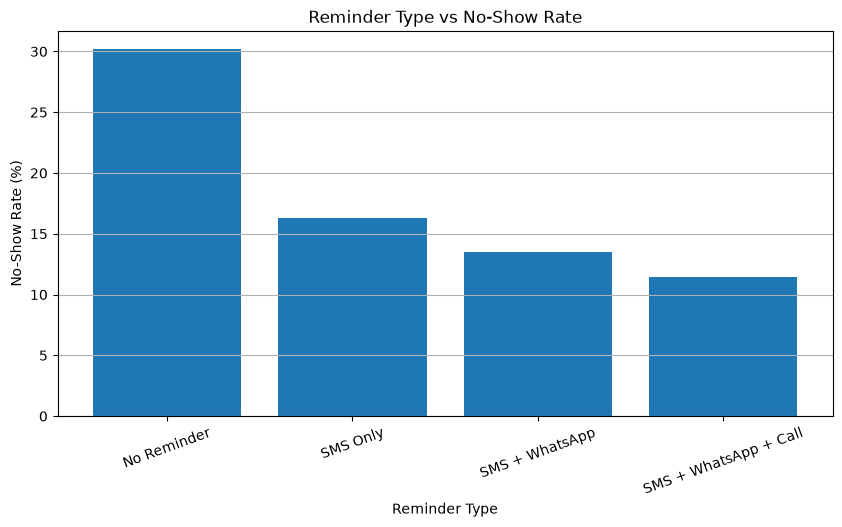

In [24]:
plt.figure(figsize=(10,5))

plt.bar(
    reminder_analysis["reminder_type"],
    reminder_analysis["no_show_rate"]
)

plt.title("Reminder Type vs No-Show Rate")
plt.xlabel("Reminder Type")
plt.ylabel("No-Show Rate (%)")
plt.xticks(rotation=20)
plt.grid(axis="y")
plt.show()

#q2. Does prior no-show history predict future no-show behaviour?

In [25]:
no_show_data = data[
    data["appointment_status"].isin(["Completed", "No-Show", "Cancelled"])
].copy()

no_show_data["is_no_show"] = (
    no_show_data["appointment_status"] == "No-Show"
).astype(int)

In [26]:
no_show_data["prior_no_show_group"] = no_show_data["patient_prior_no_shows"].apply(
    lambda x: "0 Previous No-Shows" if x == 0
    else ("1 Previous No-Show" if x == 1 else "2+ Previous No-Shows")
)

In [27]:
prior_analysis = no_show_data.groupby("prior_no_show_group").agg(
    total_appointments=("appointment_id", "count"),
    no_show_appointments=("is_no_show", "sum")
).reset_index()

prior_analysis["no_show_rate"] = (
    prior_analysis["no_show_appointments"] /
    prior_analysis["total_appointments"]
) * 100

prior_analysis = prior_analysis.sort_values(
    by="prior_no_show_group"
)

print(prior_analysis)

    prior_no_show_group  total_appointments  no_show_appointments  \
0   0 Previous No-Shows               63014                  9549   
1    1 Previous No-Show                8502                  1723   
2  2+ Previous No-Shows                1136                   312   

   no_show_rate  
0     15.153775  
1     20.265820  
2     27.464789  


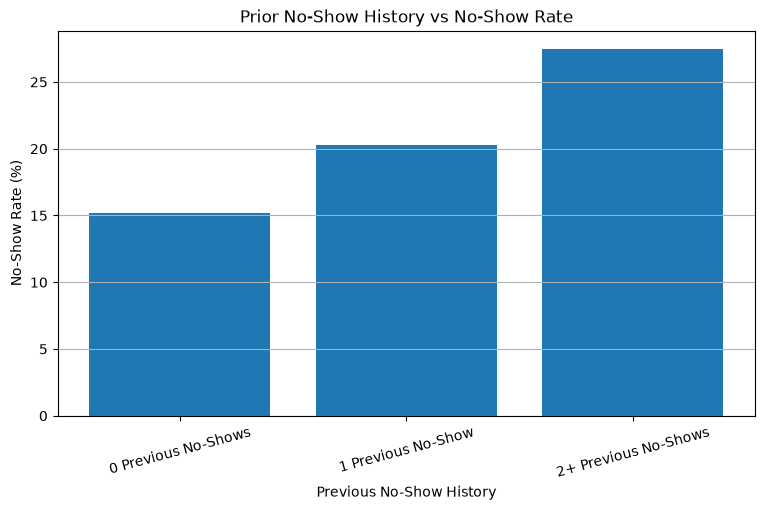

In [28]:
plt.figure(figsize=(9,5))

plt.bar(
    prior_analysis["prior_no_show_group"].astype(str),
    prior_analysis["no_show_rate"]
)

plt.title("Prior No-Show History vs No-Show Rate")
plt.xlabel("Previous No-Show History")
plt.ylabel("No-Show Rate (%)")
plt.xticks(rotation=15)
plt.grid(axis="y")
plt.show()

#q3.- Do Apollo members and repeat patients show better attendance than non-members and first-time patients?

In [29]:
member_data = data[
    data["appointment_status"].isin(["Completed", "No-Show", "Cancelled"])
].copy()

member_data["is_no_show"] = (
    member_data["appointment_status"] == "No-Show"
).astype(int)

member_data["is_attended"] = (
    member_data["appointment_status"] == "Completed"
).astype(int)

In [30]:
member_analysis = member_data.groupby("apollo_member").agg(
    total_appointments=("appointment_id", "count"),
    attended_appointments=("is_attended", "sum"),
    no_show_appointments=("is_no_show", "sum")
).reset_index()

member_analysis["attendance_rate"] = (
    member_analysis["attended_appointments"] /
    member_analysis["total_appointments"]
) * 100

member_analysis["no_show_rate"] = (
    member_analysis["no_show_appointments"] /
    member_analysis["total_appointments"]
) * 100

print(member_analysis.round(2))

  apollo_member  total_appointments  attended_appointments  \
0            No               56428                  42402   
1           Yes               16224                  12873   

   no_show_appointments  attendance_rate  no_show_rate  
0                  9530            75.14         16.89  
1                  2054            79.35         12.66  


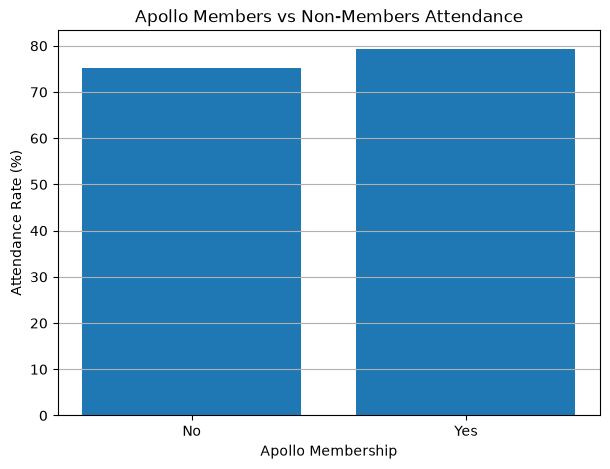

In [32]:
plt.figure(figsize=(7,5))

plt.bar(
    member_analysis["apollo_member"],
    member_analysis["attendance_rate"]
)

plt.title("Apollo Members vs Non-Members Attendance")
plt.xlabel("Apollo Membership")
plt.ylabel("Attendance Rate (%)")
plt.grid(axis="y")
plt.show()

In [31]:
visit_analysis = member_data.groupby("repeat_visit").agg(
    total_appointments=("appointment_id", "count"),
    attended_appointments=("is_attended", "sum"),
    no_show_appointments=("is_no_show", "sum")
).reset_index()

visit_analysis["attendance_rate"] = (
    visit_analysis["attended_appointments"] /
    visit_analysis["total_appointments"]
) * 100

visit_analysis["no_show_rate"] = (
    visit_analysis["no_show_appointments"] /
    visit_analysis["total_appointments"]
) * 100

print(visit_analysis.round(2))

  repeat_visit  total_appointments  attended_appointments  \
0           No                9182                      0   
1          Yes               63470                  55275   

   no_show_appointments  attendance_rate  no_show_rate  
0                  6132             0.00         66.78  
1                  5452            87.09          8.59  


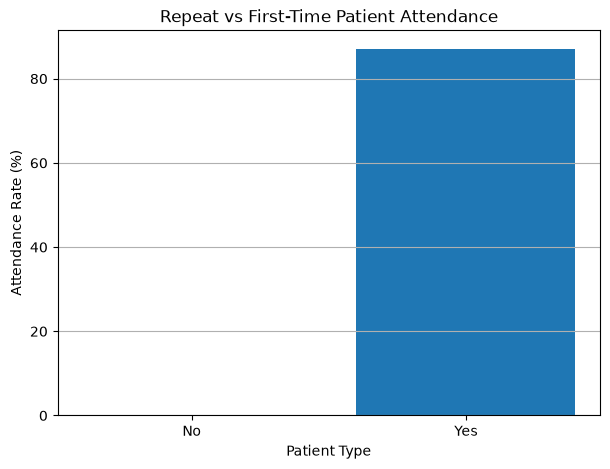

In [33]:
plt.figure(figsize=(7,5))

plt.bar(
    visit_analysis["repeat_visit"],
    visit_analysis["attendance_rate"]
)

plt.title("Repeat vs First-Time Patient Attendance")
plt.xlabel("Patient Type")
plt.ylabel("Attendance Rate (%)")
plt.grid(axis="y")
plt.show()

Patient and Demographic Segmentation 

#q1.How do age group, gender, and chronic condition status influence no-show likelihood? 

In [34]:
age_analysis = data[
    data["appointment_status"].isin(["Completed", "No-Show", "Cancelled"])
].copy()

age_analysis["is_no_show"] = (
    age_analysis["appointment_status"] == "No-Show"
).astype(int)

age_result = age_analysis.groupby("age_group").agg(
    total_appointments=("appointment_id", "count"),
    no_show_appointments=("is_no_show", "sum")
).reset_index()

age_result["no_show_rate"] = (
    age_result["no_show_appointments"] /
    age_result["total_appointments"]
) * 100

age_result = age_result.sort_values(
    by="no_show_rate", ascending=False
)

age_result

,age_group,total_appointments,no_show_appointments,no_show_rate
0,Adult (31-45),15133,2731,18.046653
5,Young Adult (19-30),10017,1797,17.939503
2,Middle-aged (46-60),14862,2491,16.760867
4,Teen (13-18),6379,939,14.720176
3,Senior (60+),14516,2036,14.025902
1,Child (0-12),11745,1590,13.537676


In [35]:
gender_analysis = data[
    data["appointment_status"].isin(["Completed", "No-Show", "Cancelled"])
].copy()

gender_analysis["is_no_show"] = (
    gender_analysis["appointment_status"] == "No-Show"
).astype(int)

gender_result = gender_analysis.groupby("patient_gender").agg(
    total_appointments=("appointment_id", "count"),
    no_show_appointments=("is_no_show", "sum")
).reset_index()

gender_result["no_show_rate"] = (
    gender_result["no_show_appointments"] /
    gender_result["total_appointments"]
) * 100

gender_result

,patient_gender,total_appointments,no_show_appointments,no_show_rate
0,Female,37589,6029,16.039267
1,Male,35063,5555,15.842911


In [36]:
chronic_analysis = data[
    data["appointment_status"].isin(["Completed", "No-Show", "Cancelled"])
].copy()

chronic_analysis["is_no_show"] = (
    chronic_analysis["appointment_status"] == "No-Show"
).astype(int)

chronic_result = chronic_analysis.groupby(
    "patient_chronic_condition"
).agg(
    total_appointments=("appointment_id", "count"),
    no_show_appointments=("is_no_show", "sum")
).reset_index()

chronic_result["no_show_rate"] = (
    chronic_result["no_show_appointments"] /
    chronic_result["total_appointments"]
) * 100

chronic_result = chronic_result.sort_values(
    by="no_show_rate", ascending=False
)

chronic_result

,patient_chronic_condition,total_appointments,no_show_appointments,no_show_rate
0,Asthma,9098,1520,16.706969
2,Heart Disease,9155,1494,16.318951
5,None,27144,4314,15.893015
1,Diabetes,9010,1421,15.771365
3,Hypertension,9100,1417,15.571429
4,Hypothyroidism,9145,1418,15.505741


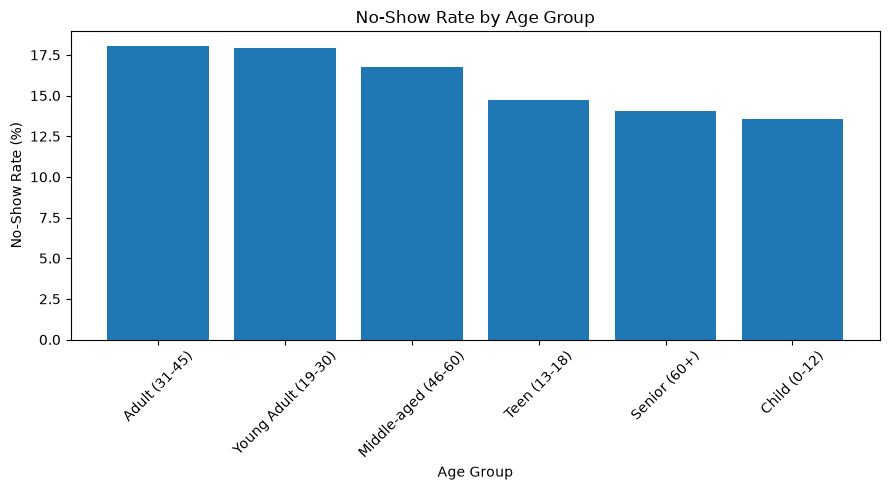

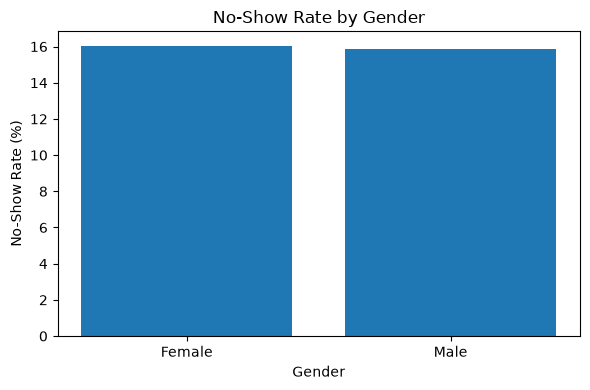

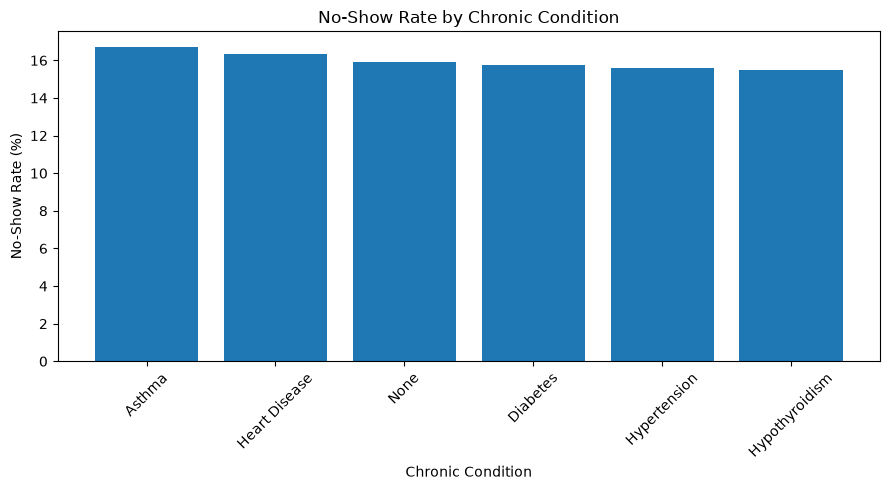

In [37]:
import matplotlib.pyplot as plt

# Age Group Chart
plt.figure(figsize=(9, 5))
plt.bar(age_result["age_group"], age_result["no_show_rate"])
plt.title("No-Show Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("No-Show Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Gender Chart
plt.figure(figsize=(6, 4))
plt.bar(gender_result["patient_gender"], gender_result["no_show_rate"])
plt.title("No-Show Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("No-Show Rate (%)")
plt.tight_layout()
plt.show()


# Chronic Condition Chart
plt.figure(figsize=(9, 5))
plt.bar(
    chronic_result["patient_chronic_condition"],
    chronic_result["no_show_rate"]
)
plt.title("No-Show Rate by Chronic Condition")
plt.xlabel("Chronic Condition")
plt.ylabel("No-Show Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#q2.Which visit reasons are most common and are some associated with higher dropout? 

In [38]:
visit_count = data["visit_reason"].value_counts().reset_index()

visit_count.columns = ["visit_reason", "total_bookings"]

visit_count

,visit_reason,total_bookings
0,Follow-up,8807
1,Routine Checkup,8637
2,Chronic Condition Management,8380
3,Digestive Problem,8245
4,Fever & Infection,7041
5,Joint Pain,6664
6,Respiratory Issue,6590
7,Injury,6087
8,Eye Care,2959
9,Skin Issue,2862


In [39]:
visit_data = data[
    data["appointment_status"].isin(["Completed", "No-Show", "Cancelled"])
].copy()

visit_data["is_no_show"] = (
    visit_data["appointment_status"] == "No-Show"
).astype(int)

visit_data["is_dropout"] = (
    visit_data["appointment_status"].isin(["No-Show", "Cancelled"])
).astype(int)

visit_result = visit_data.groupby("visit_reason").agg(
    total_appointments=("appointment_id", "count"),
    no_show_appointments=("is_no_show", "sum"),
    dropout_appointments=("is_dropout", "sum")
).reset_index()

visit_result["no_show_rate"] = (
    visit_result["no_show_appointments"] /
    visit_result["total_appointments"]
) * 100

visit_result["dropout_rate"] = (
    visit_result["dropout_appointments"] /
    visit_result["total_appointments"]
) * 100

visit_result = visit_result.sort_values(
    by="dropout_rate", ascending=False
)

visit_result.round(2)

,visit_reason,total_appointments,no_show_appointments,dropout_appointments,no_show_rate,dropout_rate
9,Mental Health,2733,445,687,16.28,25.14
12,Skin Issue,2782,467,689,16.79,24.77
8,Joint Pain,6469,1082,1589,16.73,24.56
10,Respiratory Issue,6383,1020,1566,15.98,24.53
2,Chronic Condition Management,8117,1266,1972,15.60,24.29
0,Cardiac Concern,2639,430,637,16.29,24.14
3,Digestive Problem,7984,1297,1924,16.24,24.10
7,Injury,5884,949,1402,16.13,23.83
5,Fever & Infection,6808,1095,1612,16.08,23.68
13,Women's Health,2362,377,557,15.96,23.58


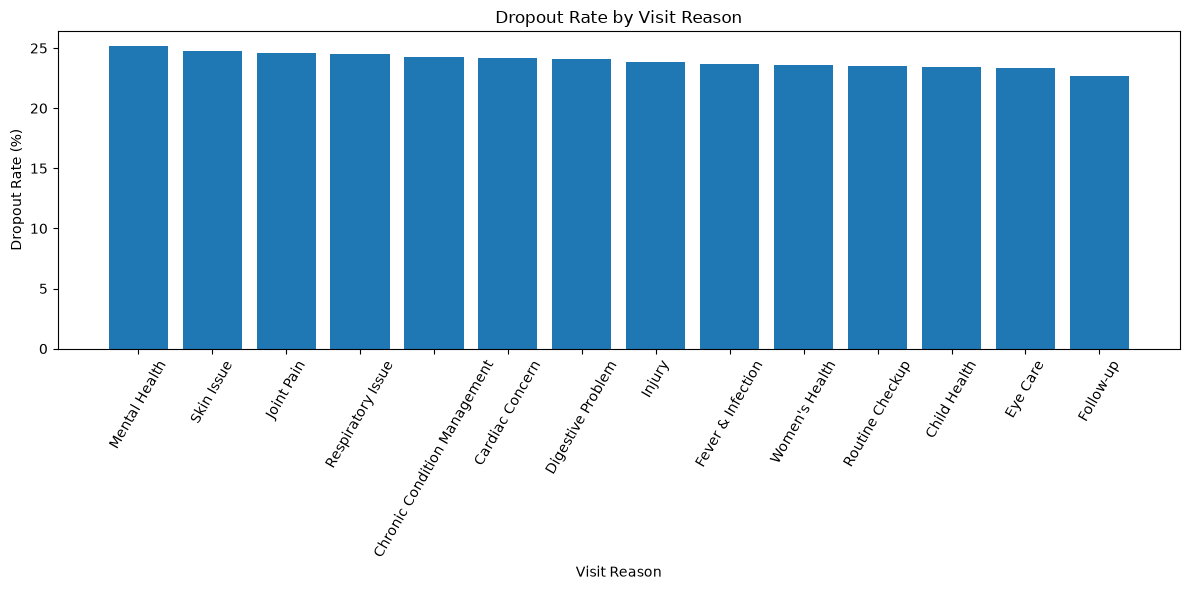

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    visit_result["visit_reason"],
    visit_result["dropout_rate"]
)

plt.title("Dropout Rate by Visit Reason")
plt.xlabel("Visit Reason")
plt.ylabel("Dropout Rate (%)")

plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

#q3.What does the patient age distribution look like within specialties like Paediatrics, Gynaecology, and Psychiatry?

age_group    Child (0-12)  Teen (13-18)  Young Adult (19-30)  Adult (31-45)  \
specialty                                                                     
Gynaecology          11.7           6.1                 14.7           23.6   
Paediatrics          68.2          31.8                  0.0            0.0   
Psychiatry           10.9           7.1                 14.4           22.3   

age_group    Middle-aged (46-60)  Senior (60+)  
specialty                                       
Gynaecology                 21.6          22.3  
Paediatrics                  0.0           0.0  
Psychiatry                  22.3          22.9  


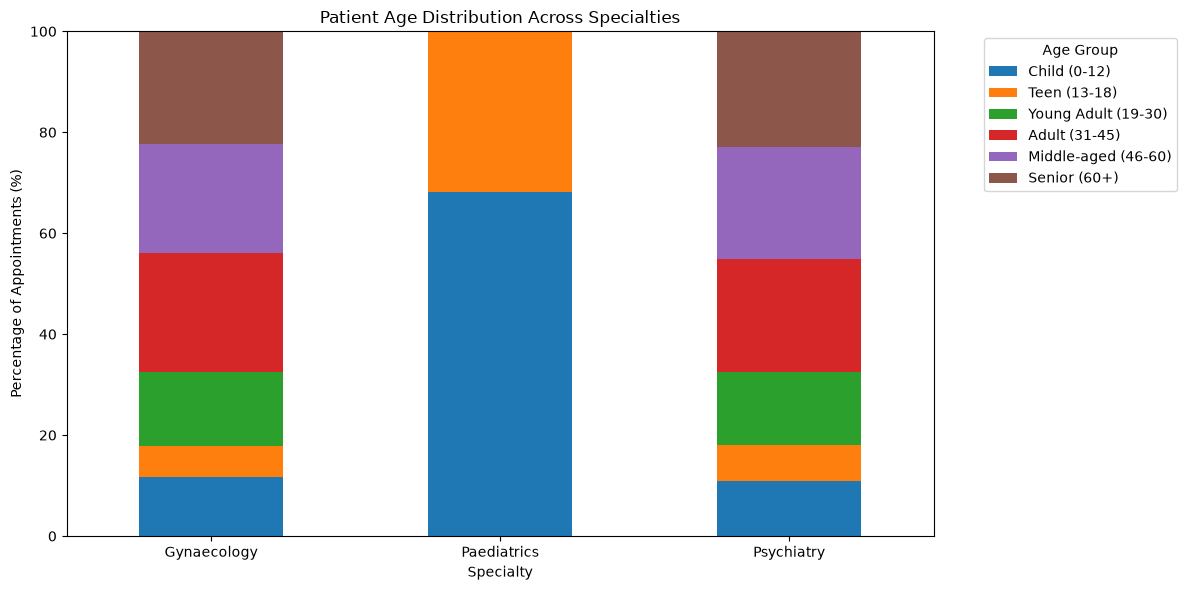

In [41]:
import matplotlib.pyplot as plt

specialties = ["Paediatrics", "Gynaecology", "Psychiatry"]

age_data = data[data["specialty"].isin(specialties)]

age_distribution = pd.crosstab(
    age_data["specialty"],
    age_data["age_group"],
    normalize="index"
) * 100

age_distribution = age_distribution[
    ["Child (0-12)", "Teen (13-18)", "Young Adult (19-30)",
     "Adult (31-45)", "Middle-aged (46-60)", "Senior (60+)"]
]

print(age_distribution.round(1))

age_distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Patient Age Distribution Across Specialties")
plt.xlabel("Specialty")
plt.ylabel("Percentage of Appointments (%)")
plt.xticks(rotation=0)
plt.legend(title="Age Group", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

Financial Performance 

#q1.How much revenue is being lost to no-shows?

In [42]:
no_show_data = data[
    data["appointment_status"] == "No-Show"
]

total_no_shows = no_show_data["appointment_id"].count()

lost_revenue = no_show_data["consultation_fee"].sum()

average_fee = no_show_data["consultation_fee"].mean()

print("Total No-Show Appointments:", total_no_shows)
print("Estimated Lost Revenue: ₹", lost_revenue)
print("Average Consultation Fee: ₹", round(average_fee, 2))

Total No-Show Appointments: 11584
Estimated Lost Revenue: ₹ 19725460
Average Consultation Fee: ₹ 1702.82


#q2.How does average revenue vary across specialties and appointment types? 

In [43]:
import matplotlib.pyplot as plt

completed_data = data[
    data["appointment_status"] == "Completed"
].copy()

# Specialty-wise average revenue
specialty_revenue = completed_data.groupby("specialty").agg(
    total_appointments=("appointment_id", "count"),
    average_revenue=("revenue_realized", "mean")
).reset_index()

specialty_revenue = specialty_revenue.sort_values(
    by="average_revenue", ascending=False
)

print(specialty_revenue.round(2))

            specialty  total_appointments  average_revenue
11         Psychiatry                1958          2640.45
7           Neurology                3899          2076.48
13            Urology                1729          1988.62
0          Cardiology                3507          1940.77
4    Gastroenterology                1972          1896.82
3       Endocrinology                1504          1812.68
12        Pulmonology                1961          1803.23
9        Orthopaedics                4189          1547.20
6         Gynaecology                3134          1499.59
8       Ophthalmology                2349          1467.13
1         Dermatology                5347          1306.92
2                 ENT                3845          1204.48
10        Paediatrics                4900           949.73
5   General Physician               14981           632.79


In [44]:
appointment_revenue = completed_data.groupby("appointment_type").agg(
    total_appointments=("appointment_id", "count"),
    average_revenue=("revenue_realized", "mean")
).reset_index()

appointment_revenue = appointment_revenue.sort_values(
    by="average_revenue", ascending=False
)

print(appointment_revenue.round(2))

  appointment_type  total_appointments  average_revenue
0       Home Visit                6436          1960.05
1        In-Clinic               37938          1299.83
2    Video Consult               10901          1097.70


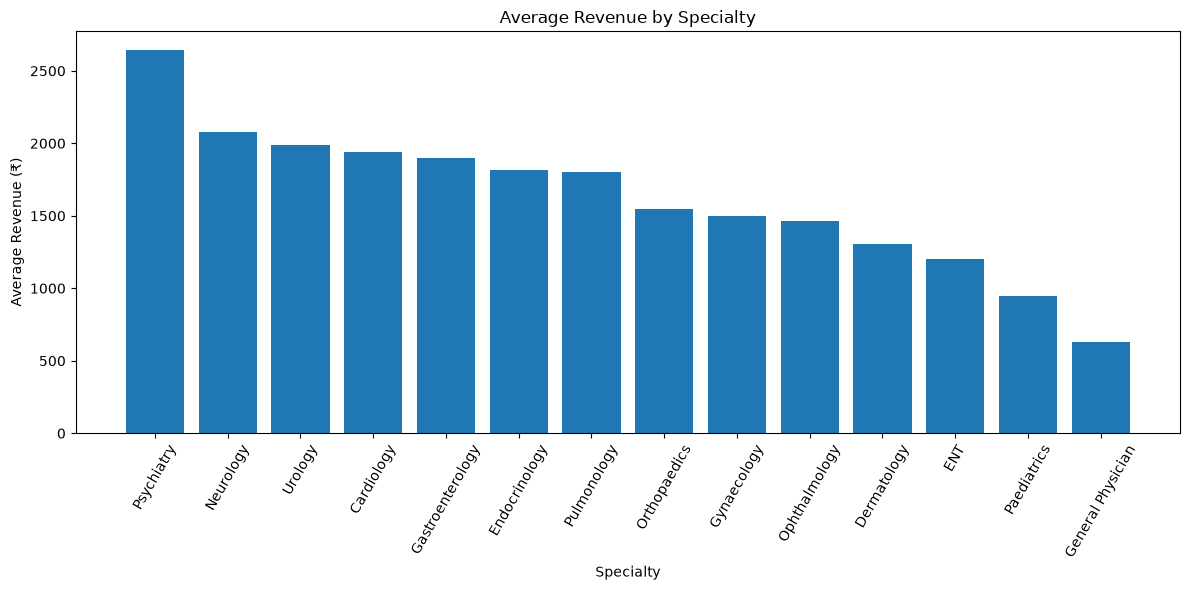

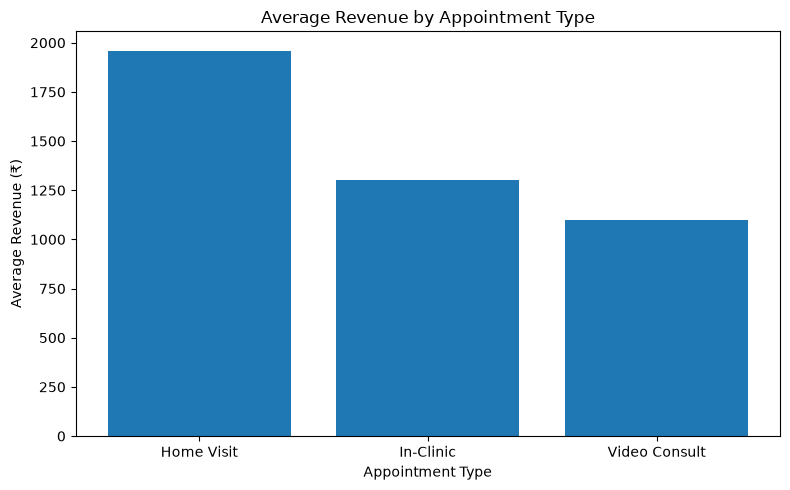

In [45]:
# Specialty-wise chart
plt.figure(figsize=(12, 6))
plt.bar(
    specialty_revenue["specialty"],
    specialty_revenue["average_revenue"]
)
plt.title("Average Revenue by Specialty")
plt.xlabel("Specialty")
plt.ylabel("Average Revenue (₹)")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

# Appointment type-wise chart
plt.figure(figsize=(8, 5))
plt.bar(
    appointment_revenue["appointment_type"],
    appointment_revenue["average_revenue"]
)
plt.title("Average Revenue by Appointment Type")
plt.xlabel("Appointment Type")
plt.ylabel("Average Revenue (₹)")
plt.tight_layout()
plt.show()

#q3.Which cities generate the most revenue and what is the payment mode mix? 

In [46]:
completed_data = data[
    data["appointment_status"] == "Completed"
].copy()

city_revenue = completed_data.groupby("city").agg(
    total_appointments=("appointment_id", "count"),
    total_revenue=("revenue_realized", "sum")
).reset_index()

city_revenue = city_revenue.sort_values(
    by="total_revenue", ascending=False
)

city_revenue["revenue_share"] = (
    city_revenue["total_revenue"] /
    city_revenue["total_revenue"].sum()
) * 100

print(city_revenue.round(2))

          city  total_appointments  total_revenue  revenue_share
1    Bengaluru                6405        9990616          13.52
6        Delhi                7834        9958247          13.48
13      Mumbai                7318        8989613          12.17
7    Hyderabad                5496        7503245          10.15
4      Chennai                5132        7188473           9.73
11     Kolkata                4280        6543084           8.85
14        Pune                3179        4734139           6.41
0    Ahmedabad                2607        3956890           5.35
12     Lucknow                2254        3177444           4.30
8       Indore                1679        2223207           3.01
3   Chandigarh                1842        2221091           3.01
9       Jaipur                2005        2199116           2.98
5   Coimbatore                1696        1792804           2.43
10       Kochi                2030        1731448           2.34
2       Bhopal           

In [47]:
payment_analysis = completed_data.groupby("payment_mode").agg(
    total_appointments=("appointment_id", "count"),
    total_revenue=("revenue_realized", "sum")
).reset_index()

payment_analysis["appointment_share"] = (
    payment_analysis["total_appointments"] /
    payment_analysis["total_appointments"].sum()
) * 100

payment_analysis["revenue_share"] = (
    payment_analysis["total_revenue"] /
    payment_analysis["total_revenue"].sum()
) * 100

payment_analysis = payment_analysis.sort_values(
    by="total_revenue", ascending=False
)

print(payment_analysis.round(2))

  payment_mode  total_appointments  total_revenue  appointment_share  \
0   Apollo Pay                7324       11524032              13.25   
3   Debit Card                7353       11513741              13.30   
5  Net Banking                7349       11477401              13.30   
2  Credit Card                7213       11299512              13.05   
6          UPI                7259       11242692              13.13   
1         Cash                7136       11092328              12.91   
4    Insurance               11641        5744092              21.06   

   revenue_share  
0          15.60  
3          15.58  
5          15.53  
2          15.29  
6          15.21  
1          15.01  
4           7.77  


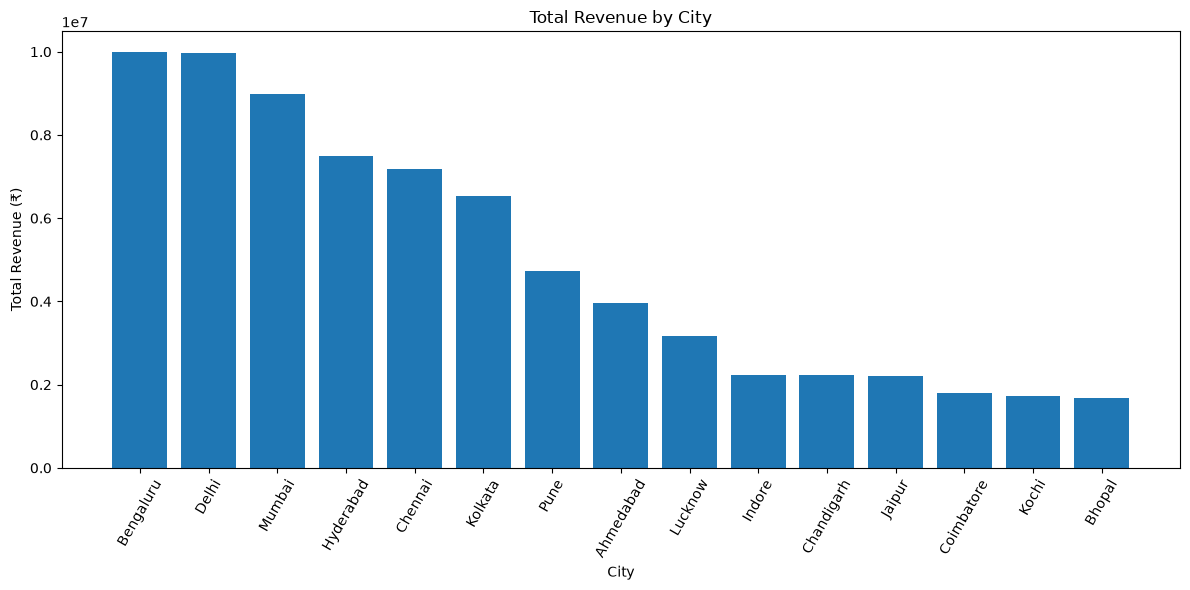

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.bar(city_revenue["city"], city_revenue["total_revenue"])

plt.title("Total Revenue by City")
plt.xlabel("City")
plt.ylabel("Total Revenue (₹)")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

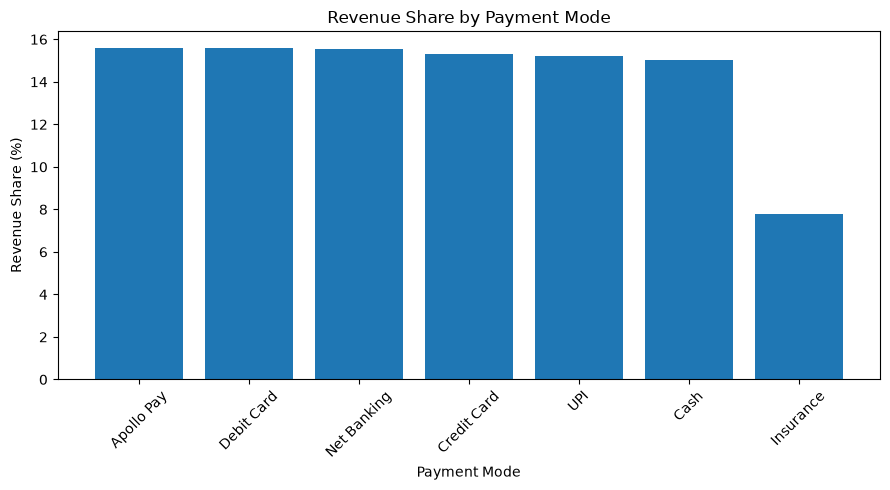

In [49]:
plt.figure(figsize=(9, 5))
plt.bar(
    payment_analysis["payment_mode"],
    payment_analysis["revenue_share"]
)

plt.title("Revenue Share by Payment Mode")
plt.xlabel("Payment Mode")
plt.ylabel("Revenue Share (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#q4.How does insurance coverage affect what patients pay out of pocket? 

In [50]:
completed_data = data[
    data["appointment_status"] == "Completed"
].copy()

insurance_analysis = completed_data.groupby("insurance_coverage").agg(
    total_appointments=("appointment_id", "count"),
    avg_actual_fee=("actual_fee_charged", "mean"),
    avg_insurance_covered=("insurance_covered_amount", "mean"),
    avg_out_of_pocket=("patient_out_of_pocket", "mean")
).reset_index()

print(insurance_analysis.round(2))

  insurance_coverage  total_appointments  avg_actual_fee  \
0                 No               37523         1562.82   
1                Yes               17752         1556.35   

   avg_insurance_covered  avg_out_of_pocket  
0                   0.00            1562.82  
1                 697.17             859.18  


In [51]:
provider_analysis = completed_data[
    completed_data["insurance_coverage"] == "Yes"
].groupby("insurance_provider").agg(
    total_appointments=("appointment_id", "count"),
    avg_insurance_covered=("insurance_covered_amount", "mean"),
    avg_out_of_pocket=("patient_out_of_pocket", "mean")
).reset_index()

provider_analysis = provider_analysis.sort_values(
    by="avg_out_of_pocket"
)

print(provider_analysis.round(2))

    insurance_provider  total_appointments  avg_insurance_covered  \
3            Niva Bupa                3541                 701.46   
1            HDFC ERGO                3497                 717.31   
0        Bajaj Allianz                3606                 694.01   
4          Star Health                3510                 692.65   
2  New India Assurance                3598                 680.96   

   avg_out_of_pocket  
3             843.61  
1             855.67  
0             856.92  
4             868.72  
2             870.84  


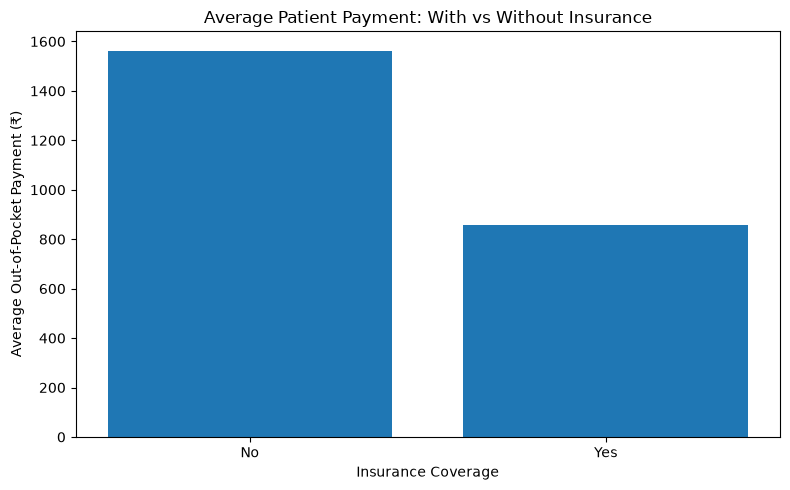

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    insurance_analysis["insurance_coverage"],
    insurance_analysis["avg_out_of_pocket"]
)

plt.title("Average Patient Payment: With vs Without Insurance")
plt.xlabel("Insurance Coverage")
plt.ylabel("Average Out-of-Pocket Payment (₹)")
plt.tight_layout()
plt.show()

Doctor Utilisation and Service Quality 

#q1.Which specialties have the highest and lowest doctor utilisation rates? 

In [53]:
completed_data = data[
    data["appointment_status"] == "Completed"
].copy()

specialty_utilisation = completed_data.groupby("specialty").agg(
    total_appointments=("appointment_id", "count"),
    total_doctors=("doctor_id", "nunique"),
    avg_utilisation=("doctor_utilization_pct", "mean")
).reset_index()

specialty_utilisation = specialty_utilisation.sort_values(
    by="avg_utilisation", ascending=False
)

print(specialty_utilisation.round(2))

            specialty  total_appointments  total_doctors  avg_utilisation
4    Gastroenterology                1972             11            77.26
3       Endocrinology                1504             10            77.15
0          Cardiology                3507             20            76.81
6         Gynaecology                3134             18            76.80
10        Paediatrics                4900             27            76.66
7           Neurology                3899             22            76.63
5   General Physician               14981             85            76.59
13            Urology                1729              9            76.44
9        Orthopaedics                4189             23            76.43
1         Dermatology                5347             34            76.42
12        Pulmonology                1961             11            76.35
2                 ENT                3845             24            76.33
8       Ophthalmology                2

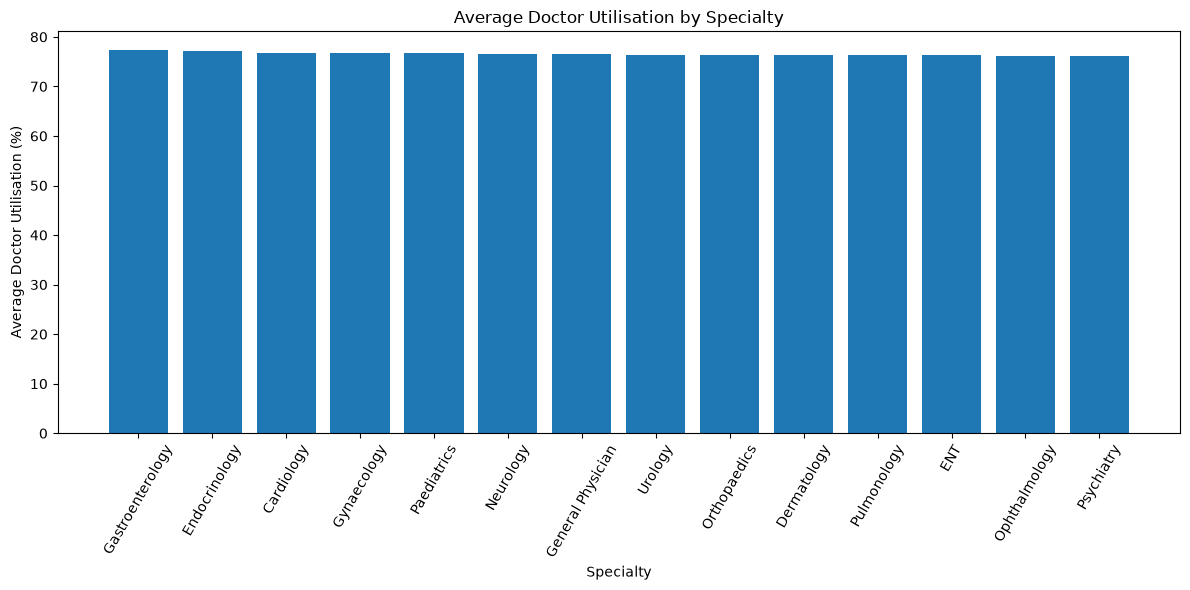

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    specialty_utilisation["specialty"],
    specialty_utilisation["avg_utilisation"]
)

plt.title("Average Doctor Utilisation by Specialty")
plt.xlabel("Specialty")
plt.ylabel("Average Doctor Utilisation (%)")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

#q2.How long are patients waiting and does it vary by specialty or time of day? 

In [55]:
completed_data = data[
    data["appointment_status"] == "Completed"
].copy()

In [56]:
specialty_wait = completed_data.groupby("specialty").agg(
    total_appointments=("appointment_id", "count"),
    avg_wait=("wait_time_minutes", "mean"),
    median_wait=("wait_time_minutes", "median")
).reset_index()

specialty_wait = specialty_wait.sort_values(
    by="avg_wait", ascending=False
)

print(specialty_wait.round(2))

            specialty  total_appointments  avg_wait  median_wait
8       Ophthalmology                2349     12.02          8.0
13            Urology                1729     11.91          8.0
1         Dermatology                5347     11.77          8.0
9        Orthopaedics                4189     11.70          8.0
7           Neurology                3899     11.64          8.0
6         Gynaecology                3134     11.62          8.0
0          Cardiology                3507     11.59          8.0
5   General Physician               14981     11.53          8.0
3       Endocrinology                1504     11.46          8.0
4    Gastroenterology                1972     11.39          8.0
12        Pulmonology                1961     11.39          8.0
11         Psychiatry                1958     11.34          8.0
2                 ENT                3845     11.30          8.0
10        Paediatrics                4900     11.18          7.0


In [57]:
time_wait = completed_data.groupby("time_of_day").agg(
    total_appointments=("appointment_id", "count"),
    avg_wait=("wait_time_minutes", "mean"),
    median_wait=("wait_time_minutes", "median")
).reset_index()

print(time_wait.round(2))

  time_of_day  total_appointments  avg_wait  median_wait
0   Afternoon               17270     11.55          8.0
1     Evening               10718     11.55          8.0
2     Morning               27287     11.55          8.0


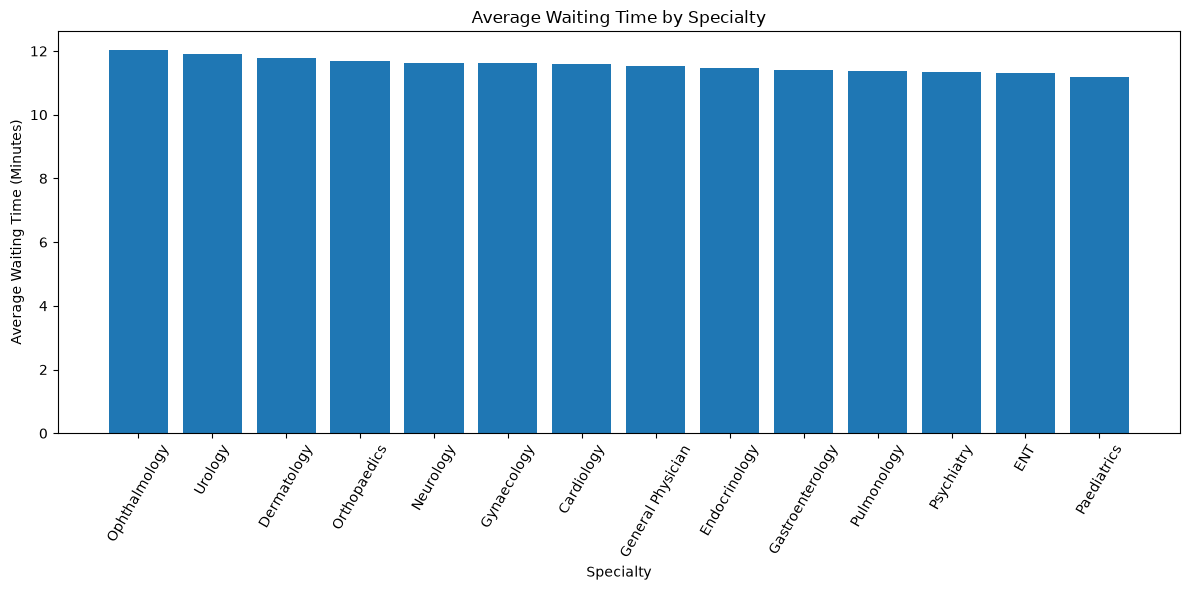

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    specialty_wait["specialty"],
    specialty_wait["avg_wait"]
)

plt.title("Average Waiting Time by Specialty")
plt.xlabel("Specialty")
plt.ylabel("Average Waiting Time (Minutes)")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

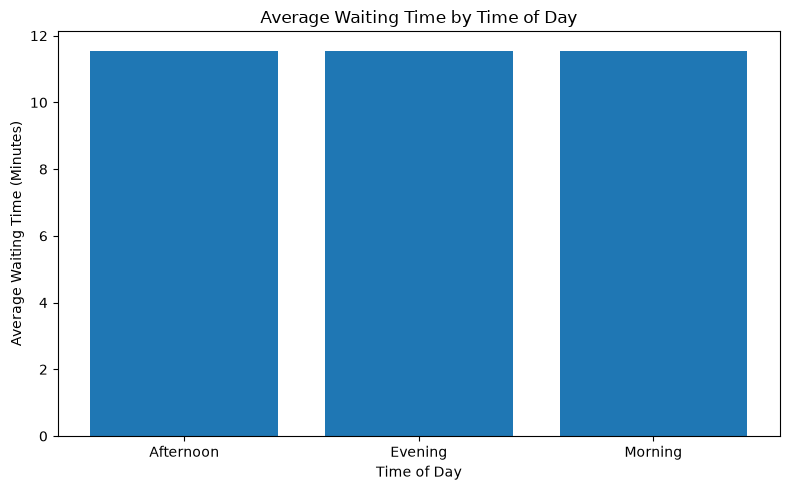

In [59]:
plt.figure(figsize=(8, 5))

plt.bar(
    time_wait["time_of_day"],
    time_wait["avg_wait"]
)

plt.title("Average Waiting Time by Time of Day")
plt.xlabel("Time of Day")
plt.ylabel("Average Waiting Time (Minutes)")
plt.tight_layout()
plt.show()

#q3.Is there a relationship between consultation duration and patient satisfaction? 

In [7]:
completed_data = data[
    data["appointment_status"] == "Completed"
].copy()

completed_data["consultation_duration_min"] = pd.to_numeric(
    completed_data["consultation_duration_min"]
)

completed_data["patient_satisfaction_score"] = pd.to_numeric(
    completed_data["patient_satisfaction_score"]
)

correlation = completed_data[
    ["consultation_duration_min", "patient_satisfaction_score"]
].corr().iloc[0, 1]

print("Correlation:", round(correlation, 4))

Correlation: -0.0035


In [9]:
completed_data = data[
    data["appointment_status"] == "Completed"
].copy()

completed_data["duration_group"] = pd.cut(
    completed_data["consultation_duration_min"],
    bins=[4, 10, 15, 20, 30, float("inf")],
    labels=["5-10 min", "11-15 min", "16-20 min", "21-30 min", "31+ min"]
)

duration_analysis = completed_data.groupby(
    "duration_group", observed=False
).agg(
    total_appointments=("appointment_id", "count"),
    avg_satisfaction=("patient_satisfaction_score", "mean")
).reset_index()

print(duration_analysis.round(2))

  duration_group  total_appointments  avg_satisfaction
0       5-10 min               11146              4.07
1      11-15 min               11864              4.07
2      16-20 min               11434              4.06
3      21-30 min               14891              4.07
4        31+ min                5940              4.07


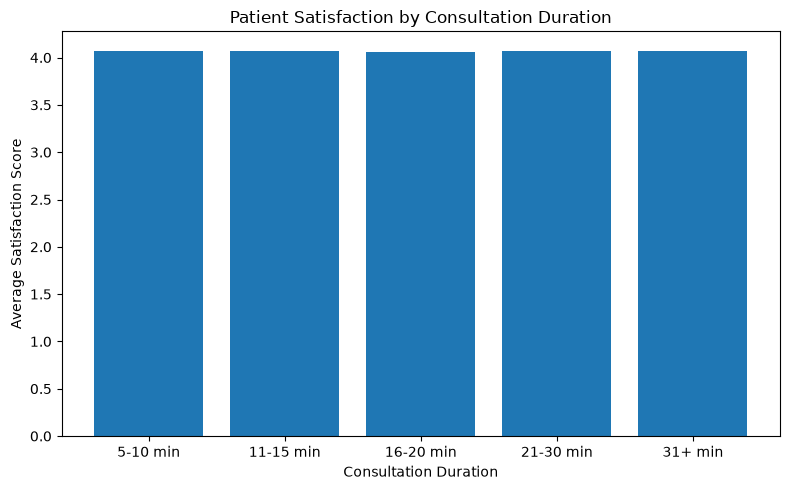

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    duration_analysis["duration_group"].astype(str),
    duration_analysis["avg_satisfaction"]
)

plt.title("Patient Satisfaction by Consultation Duration")
plt.xlabel("Consultation Duration")
plt.ylabel("Average Satisfaction Score")

plt.tight_layout()
plt.show()

#q4.How does doctor experience relate to the fee charged (join with doctors dim)? 

In [12]:
doctors = pd.read_csv("apollo_doctors_dim.csv")

#Dono tables JOIN karo

In [13]:
merged_data = data.merge(
    doctors,
    on="doctor_id",
    how="left",
    suffixes=("_fact", "_doctor")
)

print(merged_data.shape)


(75000, 66)


#Completed appointments filter karo

In [14]:
completed_data = merged_data[
    merged_data["appointment_status"] == "Completed"
].copy()

#Experience groups banao

In [15]:
completed_data["experience_group"] = pd.cut(
    completed_data["experience_years"],
    bins=[0, 5, 10, 15, 20, 25, 31],
    labels=["1-5", "6-10", "11-15", "16-20", "21-25", "26-31"]
)

#Average fee calculate karo

In [16]:
experience_analysis = completed_data.groupby(
    "experience_group", observed=False
).agg(
    total_doctors=("doctor_id", "nunique"),
    total_appointments=("appointment_id", "count"),
    avg_standard_fee=("consultation_fee_doctor", "mean"),
    avg_actual_fee=("actual_fee_charged", "mean")
).reset_index()

print(experience_analysis.round(2))

  experience_group  total_doctors  total_appointments  avg_standard_fee  \
0              1-5             51                8893           1321.57   
1             6-10             60               10491           1441.96   
2            11-15             46                7842           1494.39   
3            16-20             60               10112           1528.11   
4            21-25             54                9410           1860.69   
5            26-31             49                8527           1814.23   

   avg_actual_fee  
0         1303.67  
1         1431.91  
2         1475.98  
3         1520.55  
4         1848.37  
5         1795.55  


#Correlation Analysis

In [17]:
correlation = doctors[
    ["experience_years", "consultation_fee"]
].corr().iloc[0, 1]

print("Experience vs Consultation Fee:", round(correlation, 3))

Experience vs Consultation Fee: 0.278


#Chart – Experience vs Average Fee

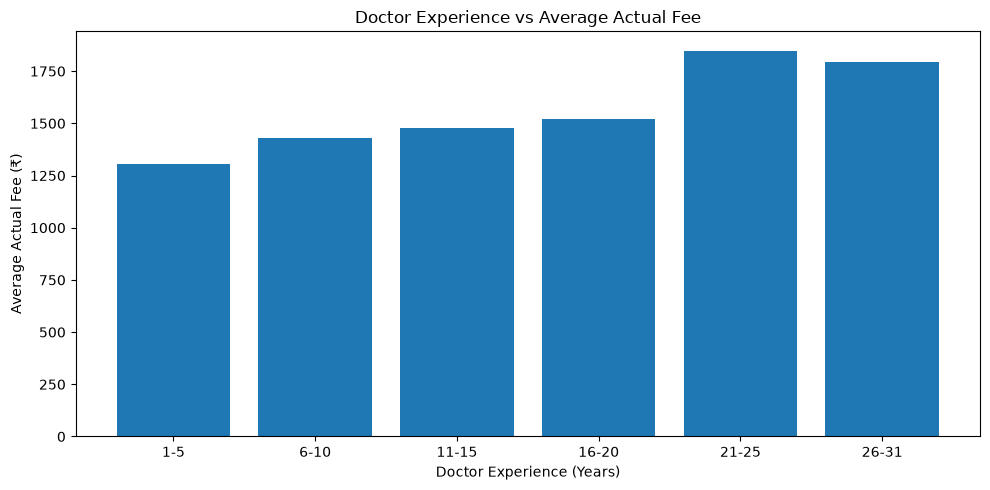

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    experience_analysis["experience_group"].astype(str),
    experience_analysis["avg_actual_fee"]
)

plt.title("Doctor Experience vs Average Actual Fee")
plt.xlabel("Doctor Experience (Years)")
plt.ylabel("Average Actual Fee (₹)")

plt.tight_layout()
plt.show()